<a href="https://colab.research.google.com/github/WaymentSteeleLab/makeshift/blob/main/demos/zoomable_spectra_Google_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
! pip -q install git+https://github.com/WaymentSteeleLab/makeshift.git ipympl

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.1/238.1 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 15.2 MB/s eta 0:00:00


In [1]:
# After running this cell, you will need to restart the session.

from google.colab import output
output.enable_custom_widget_manager()
%matplotlib widget

In [3]:
from makeshift import ChemicalShifts
from makeshift.spectra.plotting import plot_spectrum, plot_peaklist
from makeshift.spectra import Spectrum, map_peaklists

hsqc = Spectrum.example_hsqc()

peaks = hsqc.pick_peaks()
cs = ChemicalShifts.from_bmrb(4527)
pl = cs.peaklist().data

assigned, ref_translated = map_peaklists(peaks, pl)
not_mapped = ref_translated[~ref_translated['assn_label'].isin(assigned.assn_label)]

  Running grid search for best (Δ¹H, Δ¹⁵N) offset...
  Best offset: Δ¹H = -0.090, Δ¹⁵N = -0.150 ppm (RMSE = 0.678, 83/106 peaks within tolerance)
  4 conflict(s) flagged for manual inspection:
    spectrum peak 238: assigned A111,  competing A22
    spectrum peak 128: assigned M75,  competing S53
    spectrum peak 296: assigned S92,  competing Q96
    spectrum peak  67: assigned A90,  competing Q123
  94/106 peaks in right peaklist assigned  |  4 flagged for inspection


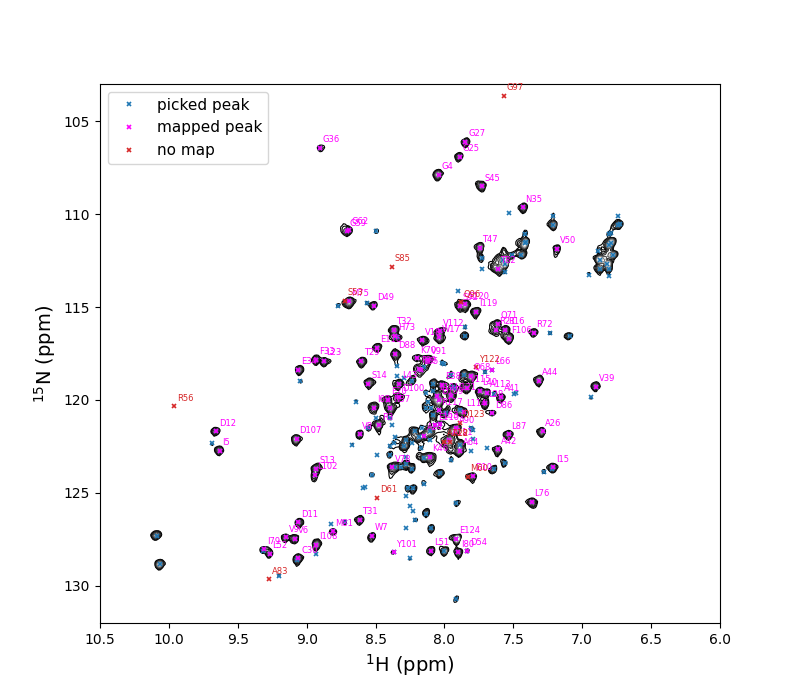

In [4]:
fig, ax = plot_spectrum(hsqc, xlim=(10.5,6), ylim=(132,103), cmap='Greys_r')
_ = plot_peaklist(peaks, ax, color='tab:blue', label='picked peak')
_ = plot_peaklist(assigned, ax, color='magenta', label='mapped peak')
_ = plot_peaklist(not_mapped, ax, text='assn_label', color='tab:red', label='no map')